# The economic costs of conflict in the Basque Country

GDP per capita, 1960–1997; comparison post-period begins 1970. Outcome: thousands of 1986 US dollars.

Abadie and Gardeazabal (2003), [AER](https://doi.org/10.1257/000282803321455188). The historical predictor specification is reproduced separately. Check Catalonia/Madrid weights against 0.851/0.149 and the upstream reference ATT of −0.699565 **over 1975–1997**. This window differs from the table's 1970–1997 ATT. The upstream Synth example includes the Spain aggregate in the donor pool; its fitted weight is zero. The paper's approximate 10% headline is not treated as an exact numeric target.

Run from a checkout installed using `requirements-replication.txt` and `pip install -e .`. Install the original R dependencies with `python scripts/install_r_references.py --library .r-library` after following [the R setup guide](../docs/reference_backends.md). The notebook downloads immutable public data with **requests**, checks the reference specification, and exports three publication figures as PDF, SVG and 300 dpi PNG. See [the replication guide](../docs/replication.md) and [the figure guide](../docs/plotting.md).

In [1]:
%matplotlib inline
import hashlib
import os
import json
import time
from dataclasses import replace
from io import BytesIO
from pathlib import Path
from importlib.metadata import version

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from pysynth import (
    SyntheticControl, SCUL, IndividualSC, TwoStageIndividualSC,
    SyntheticDID, DifferenceInDifferences, PySyncon, SCM, compare,
    plot_paths, plot_effects, plot_comparison, save_figure,
)
from pysynth.datasets import DATASETS
from pysynth.replication import (
    LITERATURE_BENCHMARKS, replicate, check_replication, reference_comparisons,
    california_paper_inference,
)
from pysynth.plotting import reference_comparison_table

pd.Series({p: version(p) for p in [
    'pysynth-control', 'numpy', 'scipy', 'pandas', 'matplotlib',
    'pysyncon', 'SyntheticControlMethods',
]}, name='version')

pysynth-control             0.1.0
numpy                       2.0.2
scipy                      1.13.1
pandas                      2.3.3
matplotlib                  3.9.4
pysyncon                    1.7.0
SyntheticControlMethods    1.1.17
Name: version, dtype: object

## Download and verify the academic data

The URL names an immutable upstream commit. SHA256 verification fails
visibly if the bytes differ. No manual download or bundled data is required.

In [2]:
name = 'basque'
spec = DATASETS[name]
response = requests.get(spec.url, timeout=30)
response.raise_for_status()
assert hashlib.sha256(response.content).hexdigest() == spec.sha256
data = pd.read_csv(BytesIO(response.content), sep=spec.separator)
panel = spec.panel(data)
print(spec.citation)
print(spec.url)
print(f'{panel.n_control} donors; {panel.n_pre} pre-periods; {panel.n_post} post-periods')
data.head()

Abadie & Gardeazabal (2003), doi:10.1257/000282803321455188
https://raw.githubusercontent.com/sdfordham/pysyncon/b77dc20e29b012ab03ca1d4caeef7b41861e86f5/data/basque.csv
17 donors; 10 pre-periods; 28 post-periods


,regionno,regionname,year,gdpcap,sec.agriculture,sec.energy,sec.industry,sec.construction,sec.services.venta,sec.services.nonventa,school.illit,school.prim,school.med,school.high,school.post.high,popdens,invest
0,1.0,Spain (Espana),1955.0,2.354542,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1.0,Spain (Espana),1956.0,2.480149,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1.0,Spain (Espana),1957.0,2.603613,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1.0,Spain (Espana),1958.0,2.637104,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1.0,Spain (Espana),1959.0,2.669880,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Reference specification and numerical check

This uses the historical specification above. Its numerical assertion is
separate from the new-method comparison. The path figure identifies the
reference estimator explicitly. See `pysynth.replication.replicate` for
predictor windows and optimization settings.

The warm-toned annotation gives the source-reported result at its stated
precision, with a source link and specification context. It is separate
from the numerical replication check. See the
[benchmark provenance](../docs/replication.md#literature-annotations)
for the paper/author-example distinction, compatible units, and the
German paper's 2025 erratum.

,label,source_label,reference,reproduced,difference,units,difference_units,window_start,window_end,statistic,approximate,citation,source_url,context
0,Historical SCM,Published,-10.000000,-10.689071,-0.689071,% of observed GDP,percentage points,1980,1997,mean_percent_effect,True,"Abadie & Gardeazabal (2003), p. 117 · 1980s–1990s",https://economics.mit.edu/sites/default/files/...,Approximate 1980s–1990s headline; available ye...
1,Historical SCM,Upstream software,-0.699565,-0.699565,0.000000,thousand 1986 US$ per capita,thousand 1986 US$ per capita,1975,1997,mean_effect,False,pysyncon parity fixture · b77dc20,https://github.com/sdfordham/pysyncon/blob/b77...,Historical predictor specification. This preci...


source                pysyncon reference ATT, 1975–1997 (not the ent...
estimate                                                      -0.699565
reference                                                     -0.699565
absolute_tolerance                                             0.017489
Name: Replication check, dtype: object

**Download figure:** [PDF](figures/basque/basque-reference.pdf) · [SVG](figures/basque/basque-reference.svg) · [PNG](figures/basque/basque-reference.png)

**Literature source:** [Abadie & Gardeazabal (2003), p. 117 · 1980s–1990s](https://economics.mit.edu/sites/default/files/publications/The%20Economic%20Costs%20of%20Conflict.pdf#page=5)

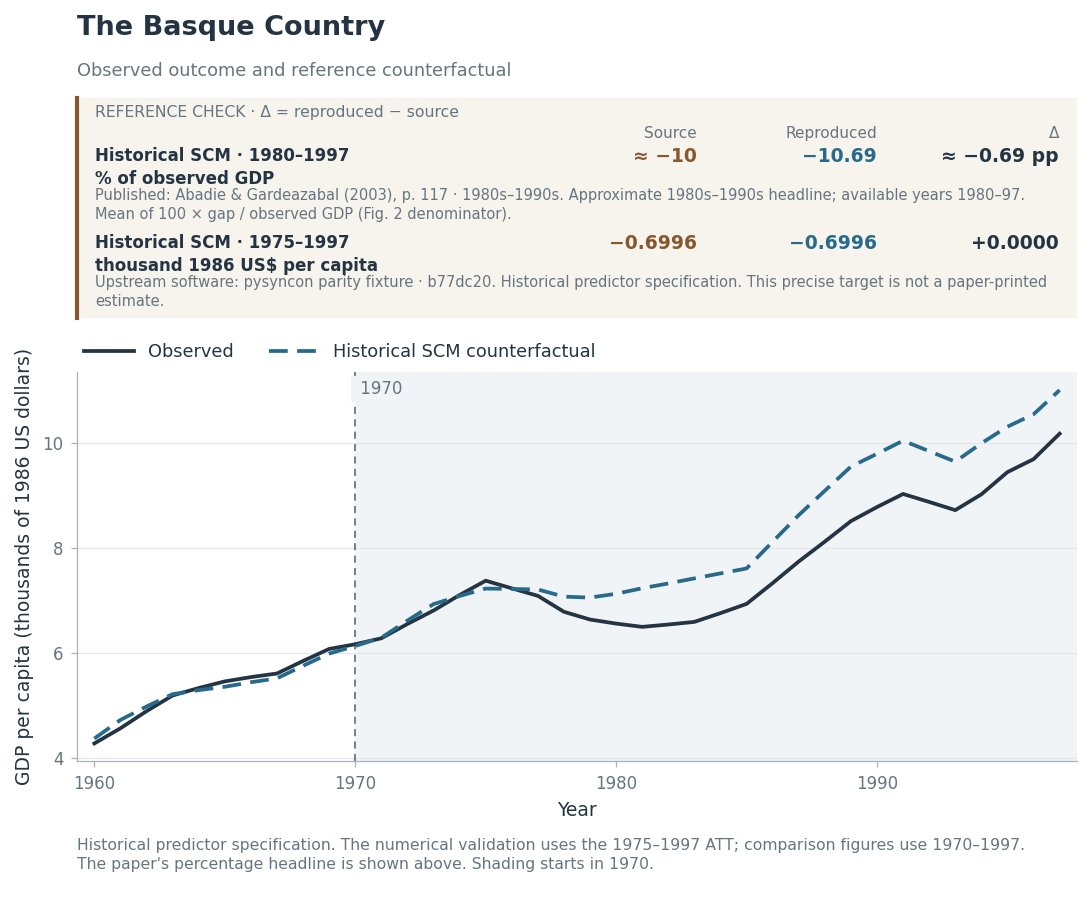

In [3]:
figure_details = {'case': 'The Basque Country', 'outcome': 'GDP per capita (thousands of 1986 US dollars)', 'effect': 'Effect on GDP per capita (thousands of 1986 US dollars)', 'units': 'thousand 1986 US$', 'periods': '1960–1969 pretreatment · 1970–1997 post-treatment · 17 donors', 'onset': '1970', 'reference': 'Historical SCM counterfactual', 'reference_note': "Historical predictor specification. The numerical validation uses the 1975–1997 ATT; comparison figures use 1970–1997. The paper's percentage headline is shown above. Shading starts in 1970."}
benchmark = LITERATURE_BENCHMARKS[name]
# Works when the kernel starts in either the repository or notebook folder.
example_dir = Path.cwd() if Path.cwd().name == 'empirical_examples' else Path.cwd() / 'empirical_examples'
figure_dir = Path(os.environ.get('PYSYNTH_FIGURE_DIR', example_dir / 'figures')) / name
figure_dir.mkdir(parents=True, exist_ok=True)

def export_figure(fig, kind):
    paths = save_figure(fig, figure_dir / f'{name}-{kind}')
    links = ' · '.join(
        f'[{p.suffix[1:].upper()}](figures/{name}/{p.name})' for p in paths
    )
    display(Markdown('**Download figure:** ' + links))
    display(Markdown(f'**Literature source:** [{benchmark.citation}]({benchmark.source_url})'))
    return paths

reference = replicate(name, data)
report = check_replication(name, reference)
additional = None
paper_uncertainty = None
if name == 'california':
    additional = {'SC': SyntheticDID().fit_sc(panel), 'DID': DifferenceInDifferences().fit(panel)}
    paper_uncertainty = california_paper_inference(panel, reference)
    se_reference = paper_uncertainty.metadata['paper_replication']['reference_standard_error']
    np.testing.assert_allclose(paper_uncertainty.standard_error, se_reference, atol=1e-9, rtol=0)
    assert abs(additional['SC'].att - (-19.6)) <= 0.05
    assert abs(additional['DID'].att - (-27.3)) <= 0.05
    report.update({'SE estimate': paper_uncertainty.standard_error,
                   'SE reference': se_reference, 'SE absolute tolerance': 1e-9})

def matched_references(fit, additional=None):
    refs = reference_comparisons(name, fit, additional=additional)
    if paper_uncertainty is not None:
        refs = [replace(r, context=r.context + (
            f' SE: paper 8.4; reproduced {paper_uncertainty.standard_error:.3f} '
            '(authors’ seed 12345).'
        )) if r.label == 'SDID' else r for r in refs]
    return refs

references = matched_references(reference, additional=additional)
reference_table = reference_comparison_table(references)
display(reference_table)
reference_table.to_csv(figure_dir / f'{name}-references.csv', index=False)
display(pd.Series(report, name='Replication check'))
ax = plot_paths(
    reference,
    title=figure_details['case'],
    subtitle='Observed outcome and reference counterfactual',
    ylabel=figure_details['outcome'], xlabel='Year',
    observed_label='Observed',
    counterfactual_label=figure_details['reference'],
    intervention_label=figure_details['onset'],
    references=references,
    note=figure_details['reference_note'],
)
reference_files = export_figure(ax.figure, 'reference')
plt.show()

## Fit all applicable methods on a common sample

Every comparison uses the same outcome panel, eligible donors and treatment
date. Classical pysyncon SCM estimates predictor importance by nested
optimization. SyntheticControlMethods uses **all pretreatment outcome
lags and all ten optimization starts**, with checked numerical recovery
when a gradient line search fails. Neither adapter truncates the fit
to accelerate this example. Native outcome SCM is retained as the
explicitly named equal-period baseline.

SCUL calls the pinned original R functions and glmnet, selecting
`lambda.median` from fold-specific paths. Its rolling validation windows
are stated in code. Basque has only ten pretreatment observations, so
its validation horizon must be shorter than its 28-period post window.
Penalized and robust SCM retain the explicit illustrative tuning values
shown below; these are new applications, not paper-specific calibrations.

ISC calls **MSCMT**, using the costofcare bootstrap workflow with **50
donor resamples**. 2SISC first selects up to ten nearest donors, then
runs the same ISC procedure within that group. These aggregate panels
do not provide the survey-specific demographic predictors, eligibility
rules, or individual sampling design of the original ISC studies.

SDID uses donor post-period outcomes to estimate time weights; robust
SCM uses them for donor denoising. Neither fits to treated post-outcomes.
Each model runs in full; failures stop execution. Elapsed fitting times
and optimizer diagnostics are exported alongside the estimates.

In [4]:
scul_windows = {'california': (5, 12), 'basque': (3, 5),
                'germany': (14, 14), 'kansas': (16, 16)}
initial, horizon = scul_windows[name]
models = {
    'Outcome SCM': SyntheticControl(),
    'SCUL': SCUL(initial_window=initial, horizon=horizon),
    'ISC (full donor pool)': IndividualSC(),
    '2SISC (nearest 10)': TwoStageIndividualSC(n_neighbors=10),
    'Synthetic DID': SyntheticDID(),
    'DID': DifferenceInDifferences(),
    'pysyncon SCM': PySyncon('synth'),
    'Augmented SCM': PySyncon('augsynth'),
    'Penalized SCM (0.01)': PySyncon('pensynth', options={'lambda_': 0.01}),
    'Robust SCM (rank 3, ridge 0.1)': PySyncon('robust', options={'lambda_': 0.1, 'sv_count': 3}),
    'SyntheticControlMethods SCM': SCM('synth'),
    'Differenced SCM': SCM('diffsynth'),
}
results, elapsed = {}, {}
for label, model in models.items():
    started = time.perf_counter()
    results[label] = model.fit(panel)
    elapsed[label] = time.perf_counter() - started
    print(f'{label}: {elapsed[label]:.2f} seconds')
comparison = compare(results)
comparison['elapsed_seconds'] = pd.Series(elapsed)
if name == 'california':
    references = matched_references(results['Synthetic DID'], additional={
        'SC': additional['SC'], 'DID': results['DID'],
    })
elif name == 'kansas':
    references = matched_references(results['Augmented SCM'])
diagnostics = {label: fit.metadata for label, fit in results.items()}
(figure_dir / f'{name}-diagnostics.json').write_text(
    json.dumps(diagnostics, indent=2, default=str) + '\n'
)
display_labels = {
    'ISC (full donor pool)': 'ISC · full donor pool',
    '2SISC (nearest 10)': '2SISC · nearest 10',
    'pysyncon SCM': 'SCM · pysyncon',
    'Penalized SCM (0.01)': 'Penalized SCM · λ = 0.01',
    'Robust SCM (rank 3, ridge 0.1)': 'Robust SCM · rank 3',
    'SyntheticControlMethods SCM': 'SCM · SCMethods',
    'Differenced SCM': 'Differenced SCM',
}
comparison.round(4)

Outcome SCM: 0.00 seconds


SCUL: 0.52 seconds


ISC (full donor pool): 0.54 seconds


2SISC (nearest 10): 0.52 seconds
Synthetic DID: 0.03 seconds
DID: 0.00 seconds


pysyncon SCM: 0.80 seconds
Augmented SCM: 0.12 seconds
Penalized SCM (0.01): 0.03 seconds
Robust SCM (rank 3, ridge 0.1): 0.00 seconds


SyntheticControlMethods SCM: 0.13 seconds


Differenced SCM: 8.70 seconds


,att,pre_rmse,donors_used,weight_sum,elapsed_seconds
model,,,,,
Outcome SCM,-0.9823,0.0642,3,1.0000,0.0029
SCUL,-1.0396,0.0534,3,1.0842,0.5195
ISC (full donor pool),-0.8165,0.1153,6,1.0000,0.5399
2SISC (nearest 10),-0.8682,0.0834,6,1.0000,0.5152
Synthetic DID,-0.8137,0.0797,11,1.0000,0.0278
DID,-0.5196,0.1175,17,1.0000,0.0001
pysyncon SCM,-0.9719,0.0645,5,1.0000,0.8009
Augmented SCM,-1.2269,0.0007,17,1.0000,0.1159
Penalized SCM (0.01),-0.8945,0.0658,3,1.0000,0.0349


## Average effects and pretreatment fit

The left panel reports the average post-treatment gap (ATT); the right
reports pretreatment root mean squared error in the same outcome units.
Methods retain the same order in every figure. They are not ranked by
estimated effect or fit. Each dot is a point estimate: **there are no
estimated confidence intervals in these figures**. Better pretreatment
fit alone does not establish causal credibility.

The reference strip pairs each source result with its matched reproduction
and signed difference, using the same statistic and evaluation window.
Approximate paper headlines and numerical upstream examples are labelled
separately. They are not targets for every estimator.

**Download figure:** [PDF](figures/basque/basque-comparison.pdf) · [SVG](figures/basque/basque-comparison.svg) · [PNG](figures/basque/basque-comparison.png)

**Literature source:** [Abadie & Gardeazabal (2003), p. 117 · 1980s–1990s](https://economics.mit.edu/sites/default/files/publications/The%20Economic%20Costs%20of%20Conflict.pdf#page=5)

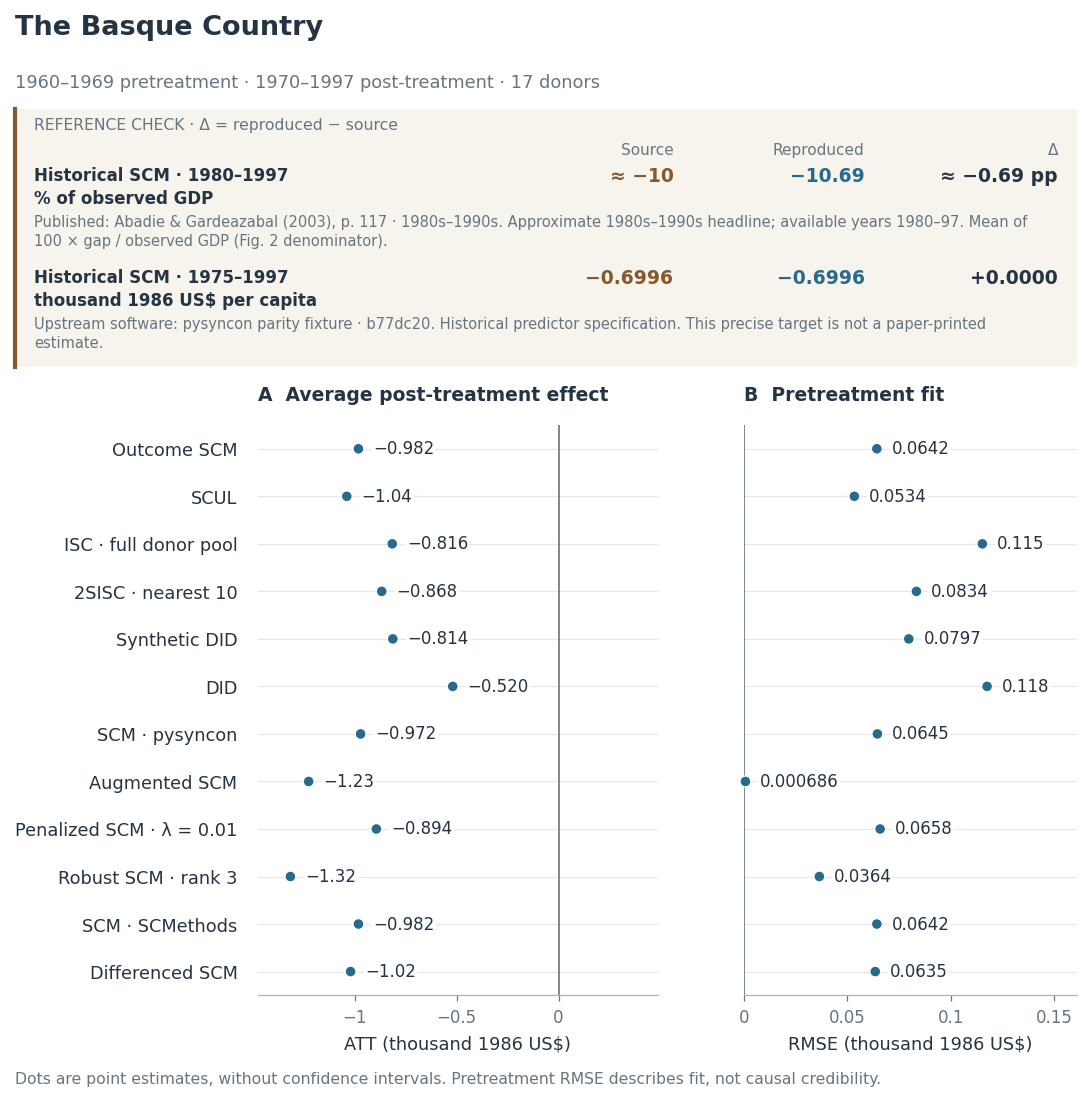

In [5]:
fig, axes = plot_comparison(
    results, labels=display_labels,
    title=figure_details['case'],
    subtitle=figure_details['periods'],
    units=figure_details['units'],
    references=references,
)
comparison_files = export_figure(fig, 'comparison')
comparison.to_csv(figure_dir / f'{name}-estimates.csv', float_format='%.12g')
plt.show()

## Effect paths on a common scale

Every panel shows **observed minus counterfactual**. All twelve panels
share the same horizontal and vertical scales; no extreme estimate is
clipped. The zero line denotes no estimated effect. The dashed vertical
line and shaded region identify the common treatment onset and post-period.
Shading does not represent uncertainty. Calendar spacing is preserved,
including quarterly observations. Panel labels replace repeated legends.
The source/reproduction strip uses matched specifications and windows.
Any numeric reference guide applies only to its matched estimator.

**Download figure:** [PDF](figures/basque/basque-effects.pdf) · [SVG](figures/basque/basque-effects.svg) · [PNG](figures/basque/basque-effects.png)

**Literature source:** [Abadie & Gardeazabal (2003), p. 117 · 1980s–1990s](https://economics.mit.edu/sites/default/files/publications/The%20Economic%20Costs%20of%20Conflict.pdf#page=5)

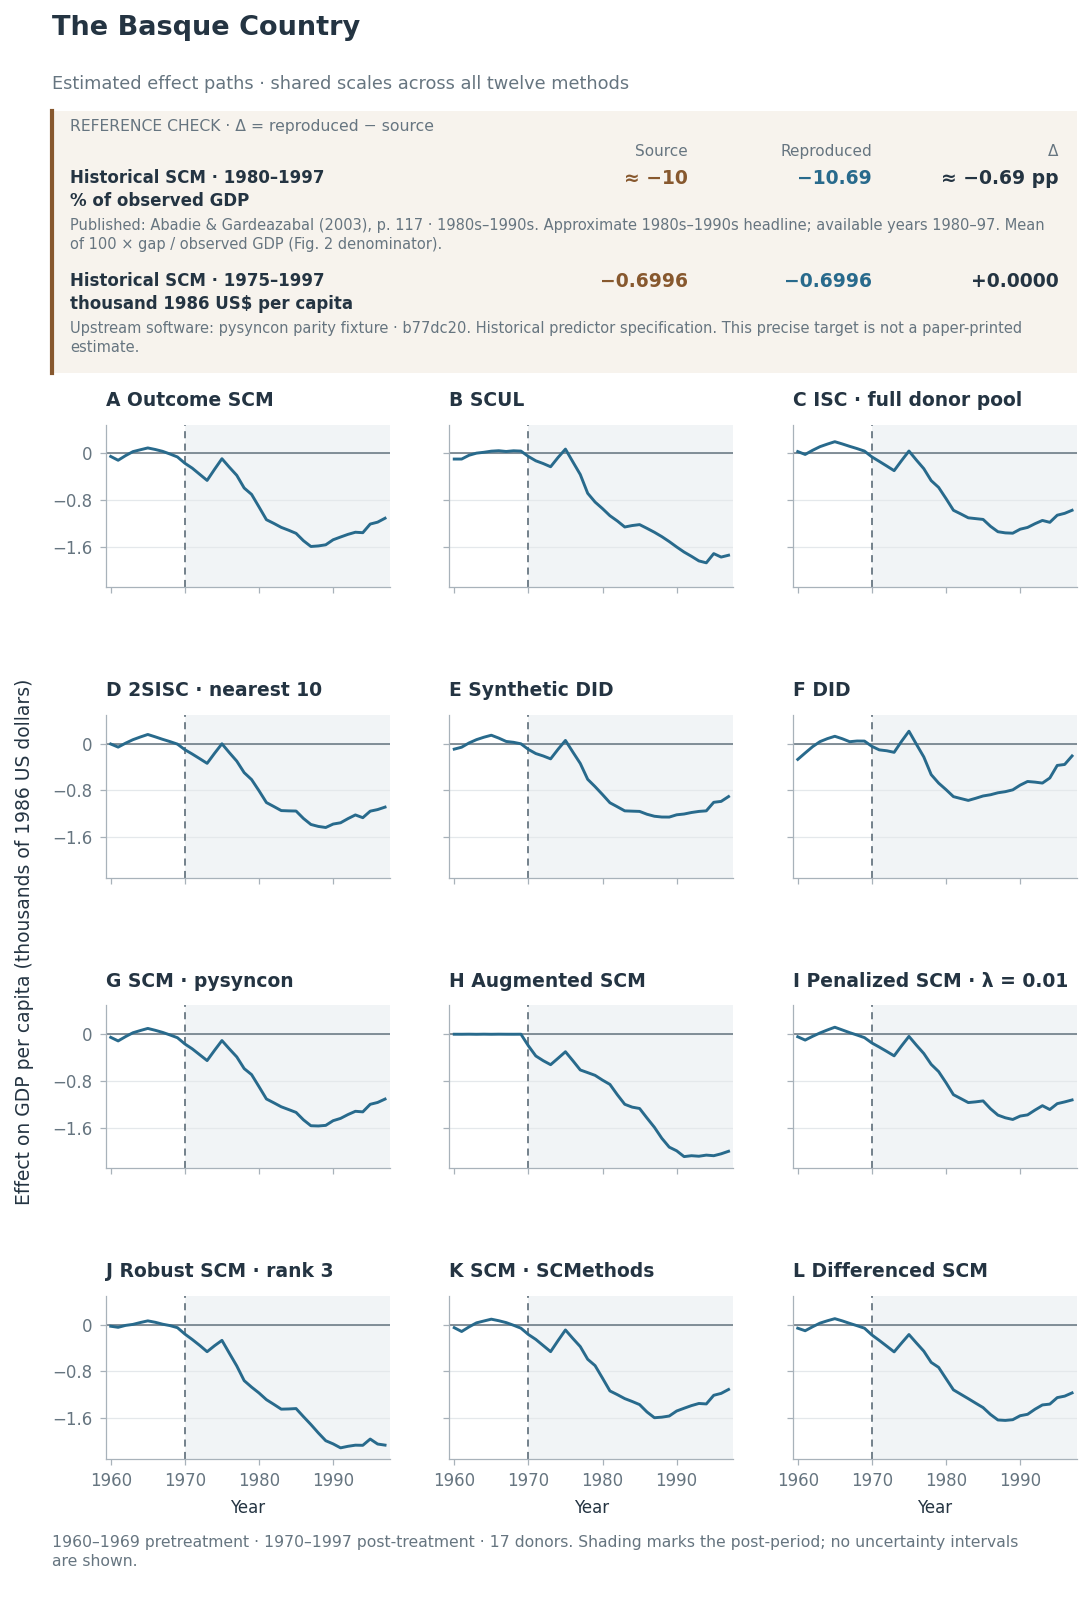

In [6]:
fig, axes = plot_effects(
    results, labels=display_labels,
    title=figure_details['case'],
    subtitle='Estimated effect paths · shared scales across all twelve methods',
    ylabel=figure_details['effect'], xlabel='Year',
    references=references,
    note=figure_details['periods'] + '. Shading marks the post-period; no uncertainty intervals are shown.',
)
effects_files = export_figure(fig, 'effects')
plt.show()

## Original SDID placebo inference and changes from the previous version

The original synthdid placebo variance estimator refits donor and time
weights in each of 200 resamples. The seed is fixed. These standard errors
apply to SDID alone; they are not intervals for the other methods.
The bootstrap and jackknife are undefined with only one treated unit.
California uses the authors' exact R sampling plan (seed 12345),
reproducing the paper's standard error 8.4 at its printed precision.
The other examples use NumPy seed 0 for reproducible new applications.

The second table compares this full fit with the archived software
outputs at commit `32d4f97`. Those earlier results used shortcuts; they
are **not published academic benchmarks**. The difference is current
ATT minus the previous software ATT on the same common sample.

In [7]:
if paper_uncertainty is not None:
    np.testing.assert_allclose(results['Synthetic DID'].att, reference.att, atol=1e-12)
    uncertainty = paper_uncertainty
else:
    uncertainty = SyntheticDID().inference(
        panel, method='placebo', replications=200, random_state=0,
        estimate=results['Synthetic DID'],
    )
inference = pd.Series({
    'SDID ATT': results['Synthetic DID'].att,
    'Placebo standard error': uncertainty.standard_error,
    '95% normal interval': uncertainty.confidence_interval(),
    'Replications': 200,
}, name='SDID inference')
display(inference)
inference.to_csv(figure_dir / f'{name}-sdid-inference.csv')
np.savetxt(figure_dir / f'{name}-sdid-resamples.csv', uncertainty.resamples, delimiter=',', fmt='%d')
np.savetxt(figure_dir / f'{name}-sdid-draws.csv', uncertainty.draws, delimiter=',')
previous_path = example_dir / 'baselines' / '32d4f97' / f'{name}-estimates.csv'
previous = pd.read_csv(previous_path, index_col=0)
changes = pd.DataFrame({
    'Previous software ATT': previous['att'],
    'Full method ATT': comparison['att'],
})
changes['Change'] = changes['Full method ATT'] - changes['Previous software ATT']
display(changes.round(5))
changes.to_csv(figure_dir / f'{name}-changes.csv', float_format='%.12g')

/tmp/ipykernel_52050/2439605557.py:5: RuntimeWarning: SDID inference: 60 of 200 draws reached max_iter before the objective-decrease stopping rule; inspect solver_diagnostics
  uncertainty = SyntheticDID().inference(


SDID ATT                                                    -0.813665
Placebo standard error                                       0.349119
95% normal interval       (-1.4979259538180978, -0.12940406446589747)
Replications                                                      200
Name: SDID inference, dtype: object

,Previous software ATT,Full method ATT,Change
model,,,
Outcome SCM,-0.98229,-0.98229,-0.00000
SCUL,-1.02877,-1.03958,-0.01081
ISC (full donor pool),-0.98229,-0.81649,0.16579
2SISC (nearest 10),-0.98229,-0.86819,0.11409
Synthetic DID,-0.81367,-0.81367,0.00000
DID,-0.51957,-0.51957,0.00000
pysyncon SCM,-0.98749,-0.97193,0.01556
Augmented SCM,-1.22688,-1.22688,-0.00000
Penalized SCM (0.01),-0.89445,-0.89445,0.00000


## Inspect the donor coefficients

These are the fifteen donors with the largest absolute coefficient in
any method, not an exhaustive donor list. The coefficients are not
renormalized. SCUL and some augmented/robust estimates can have negative
weights or weight sums different from one. Intercepts and SDID time
weights are separate components; this table does not represent them.

In [8]:
weights = pd.concat({label: fit.weights for label, fit in results.items()}, axis=1)
weights.loc[weights.abs().max(axis=1).sort_values(ascending=False).index].head(15).round(4)

,Outcome SCM,SCUL,ISC (full donor pool),2SISC (nearest 10),Synthetic DID,DID,pysyncon SCM,Augmented SCM,Penalized SCM (0.01),"Robust SCM (rank 3, ridge 0.1)",SyntheticControlMethods SCM,Differenced SCM
Rioja (La),0.1895,0.7637,0.0747,0.0547,0.1395,0.0588,0.0869,-0.0988,0.0000,0.1831,0.1895,0.0000
Navarra (Comunidad Foral De),0.0000,0.0090,0.0322,0.0268,0.1284,0.0588,0.0768,0.7496,0.0000,0.1636,0.0000,0.2684
Spain (Espana),0.0000,0.0000,0.0000,0.0000,0.0647,0.0588,0.0000,0.6591,0.0000,0.0666,0.0000,0.0000
Cataluna,0.0000,0.0000,0.3254,0.4497,0.1306,0.0588,0.1089,0.2901,0.6324,0.2010,0.0000,0.0000
Principado De Asturias,0.0000,0.0000,0.0000,0.0000,0.0351,0.0588,0.0000,-0.5269,0.0000,-0.0247,0.0000,0.0000
Murcia (Region de),0.0000,0.0000,0.0000,0.0000,0.0670,0.0588,0.0000,0.4969,0.0000,0.0323,0.0000,0.0000
Castilla-La Mancha,0.0000,0.0000,0.0000,0.0000,0.0000,0.0588,0.0000,-0.4726,0.0000,0.0135,0.0000,0.0000
Extremadura,0.0000,0.0000,0.0000,0.0000,0.0000,0.0588,0.0000,-0.4616,0.0000,0.0813,0.0000,0.0000
Madrid (Comunidad De),0.4405,0.3115,0.2568,0.2137,0.1209,0.0588,0.3845,0.3013,0.1404,0.2362,0.4405,0.3847
Galicia,0.0000,0.0000,0.0000,0.0000,0.0000,0.0588,0.0000,0.3798,0.0000,0.0273,0.0000,0.0000


## Interpretation, exports and reproducibility

Negative effects mean the observed outcome is below its estimated
untreated path. These are point estimates under different restrictions,
tuning choices and identifying assumptions. They are not an uncertainty
distribution. The historical reference check is distinct from the new
comparison specifications and their stated tuning choices.

Each figure is exported at **7.2 inches wide** in three formats: PDF with
embedded fonts, SVG with editable text, and 300 dpi PNG. The links beside
each figure download the full export. The estimator summary is also saved
as CSV. Use vector formats for manuscripts and adjust figure size, labels
and captions through the plotting API before exporting to a journal's
requirements. Nothing depends on system fonts or an external TeX install.

`pysynth.placebo_test` provides in-space RMSPE-ratio diagnostics and a rank
p-value under exchangeability assumptions; it is not synthdid's placebo
variance estimator. The original SCUL scanner-data and ISC/costofcare
survey studies are not reproduced here. Re-run from a fresh kernel to
reproduce the source checks, estimates and figures together.